In [1]:
import os
import glob
from joblib import Parallel, delayed
from time import time

import numpy as np
import pandas as pd
# import ot
# from ot import dist as ot_dist
# from ot.bregman import sinkhorn_stabilized
# from scipy.spatial.distance import cdist
import json

# from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# from matplotlib.ticker import FuncFormatter
np.random.seed(42)
sns.set_style("darkgrid")

In [2]:
# load data from ./keyword_spread.csv
data_path = './keyword_spread.csv'
df = pd.read_csv(data_path)
# view the first few rows of the dataframe
print(df.head(10))
# check the columns of the dataframe
print(df.columns)  # ['keyword', 'subreddit', 'month', 'day', 'count']
# check the shape of the dataframe
print(df.shape)  # (number of rows, number of columns)
# check the data types of the columns
print(df.dtypes)  # keyword: object, subreddit: object, month: int64, day: int64, count: int64

     keyword  subreddit    month  day  count
0  new virus  worldnews  2020-01    8      1
1  new virus  worldnews  2020-01   20      2
2  new virus  worldnews  2020-01   25      1
3  new virus  worldnews  2020-01   26      1
4  new virus  worldnews  2020-01   29      1
5  new virus  worldnews  2020-01   30      1
6  new virus  worldnews  2020-02    1      1
7  new virus  worldnews  2020-02    7      1
8  new virus  worldnews  2020-02    9      1
9  new virus  worldnews  2020-02   11      1
Index(['keyword', 'subreddit', 'month', 'day', 'count'], dtype='object')
(436778, 5)
keyword      object
subreddit    object
month        object
day           int64
count         int64
dtype: object


In [3]:
# get all combinations of keywords and subreddits
all_keywords = df['keyword'].unique()
all_subreddits = df['subreddit'].unique()

# create a new dataframe with all combinations of keywords and subreddits
full_index = pd.MultiIndex.from_product([all_keywords, all_subreddits], names=['keyword', 'subreddit'])
full_df = pd.DataFrame(index=full_index).reset_index()

# sum up counts for each (keyword, subreddit) pair
aggregated = df.groupby(['keyword', 'subreddit']).agg({'count': 'sum'}).reset_index()

# merge into full_df and fill NaN values with 0
full_df = full_df.merge(aggregated, on=['keyword', 'subreddit'], how='left').fillna(0)

In [4]:
# see the first few rows of the full dataframe
print(full_df.head(10))
# check the shape of the full dataframe
print(full_df.shape)  # should be (number of keywords * number of subreddits, 3)
# check the data types of the columns
print(full_df.dtypes)  # keyword: object, subreddit: object, count: float64

# pivot the dataframe to get a matrix of counts
pivot_df = full_df.pivot(index='keyword', columns='subreddit', values='count').fillna(0)
# convert the pivoted dataframe to a numpy array and save keywords for reference
keyword_subreddit_matrix = pivot_df.to_numpy()
keywords = pivot_df.index.to_numpy()
subreddits = pivot_df.columns.to_numpy()
# check shapes
print(keyword_subreddit_matrix.shape)  # should be (number of keywords, number of subreddits)
print(f'Number of keywords: {len(keywords)}, Number of subreddits: {len(subreddits)}')
# check sparsity of the matrix
sparsity = np.mean(keyword_subreddit_matrix == 0)
print(f'Sparsity of the matrix: {sparsity:.2%}')
avg_count = keyword_subreddit_matrix.mean()
print(f'Average count per keyword and subreddit: {avg_count:.2f}')
max_count = keyword_subreddit_matrix.max()
print(f'Maximum count per keyword and subreddit: {max_count:.2f}')
# average number of total counts per keyword
total_counts_per_keyword = keyword_subreddit_matrix.sum(axis=1)
avg_total_counts = total_counts_per_keyword.mean()
print(f'Average total counts per keyword: {avg_total_counts:.2f}')
max_total_counts = total_counts_per_keyword.max()
print(f'Maximum total counts per keyword: {max_total_counts:.2f}')
# average number of total counts per subreddit
total_counts_per_subreddit = keyword_subreddit_matrix.sum(axis=0)
avg_total_counts_subreddit = total_counts_per_subreddit.mean()
print(f'Average total counts per subreddit: {avg_total_counts_subreddit:.2f}')
max_total_counts_subreddit = total_counts_per_subreddit.max()
print(f'Maximum total counts per subreddit: {max_total_counts_subreddit:.2f}')

     keyword          subreddit  count
0  new virus          worldnews   25.0
1  new virus           collapse    2.0
2  new virus               news    1.0
3  new virus               Sino    2.0
4  new virus             canada    3.0
5  new virus          vancouver    2.0
6  new virus  EverythingScience    1.0
7  new virus           politics   19.0
8  new virus           medicine    1.0
9  new virus          China_Flu   27.0
(30071718, 3)
keyword       object
subreddit     object
count        float64
dtype: object
(145274, 207)
Number of keywords: 145274, Number of subreddits: 207
Sparsity of the matrix: 99.06%
Average count per keyword and subreddit: 0.02
Maximum count per keyword and subreddit: 2761.00
Average total counts per keyword: 3.28
Maximum total counts per keyword: 4484.00
Average total counts per subreddit: 2300.68
Maximum total counts per subreddit: 119748.00


In [5]:
# there shouldn't be any rows or columns with all zeros
assert not np.any(np.all(keyword_subreddit_matrix == 0, axis=1)), "There are keywords with zero counts across all subreddits."
assert not np.any(np.all(keyword_subreddit_matrix == 0, axis=0)), "There are subreddits with zero counts across all keywords."

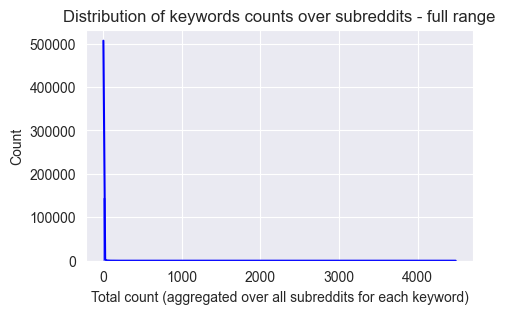

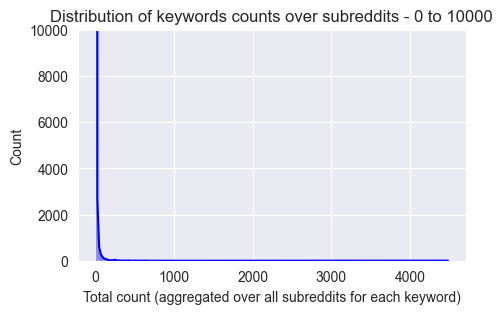

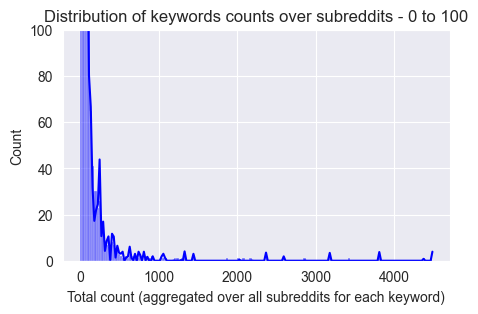

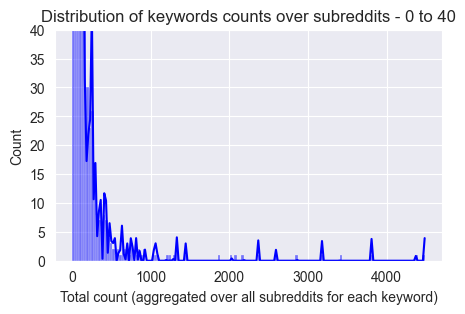

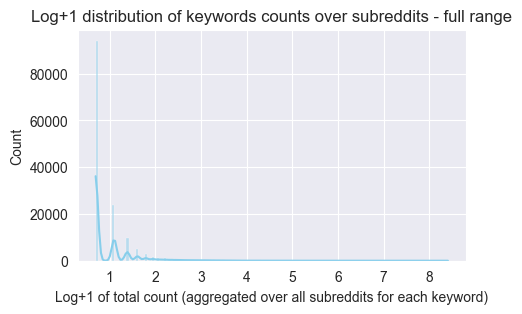

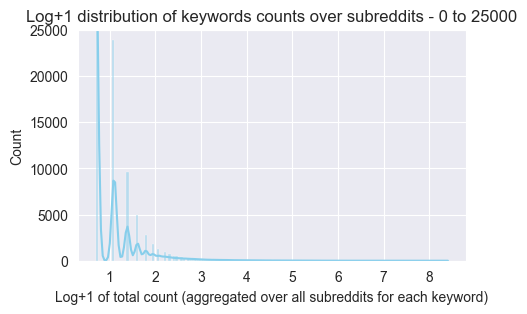

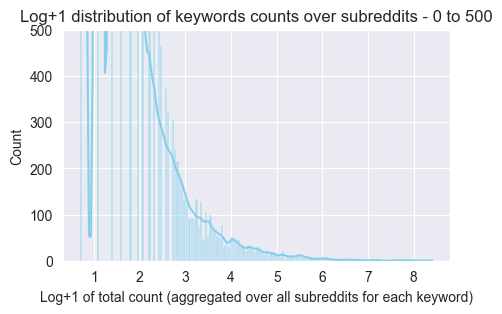

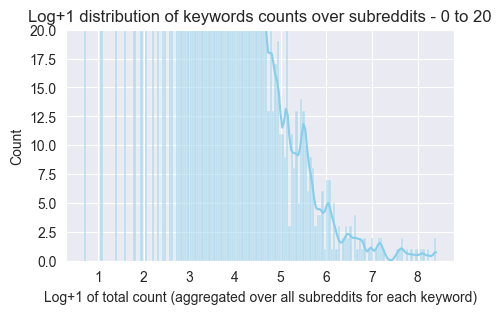

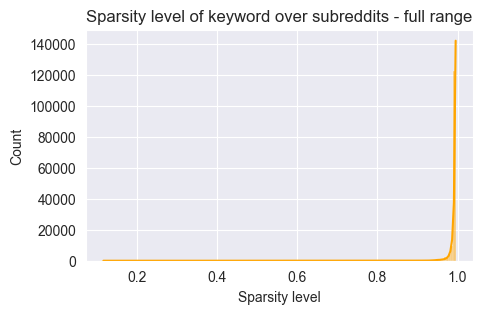

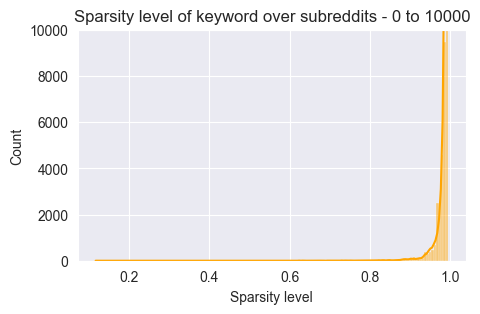

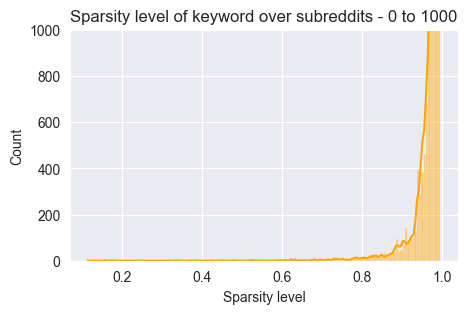

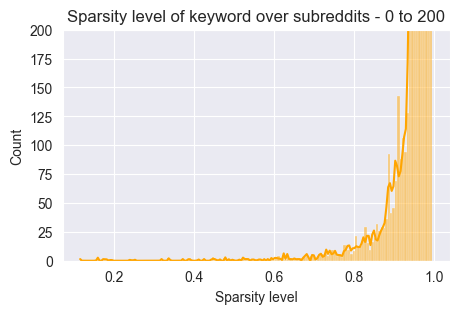

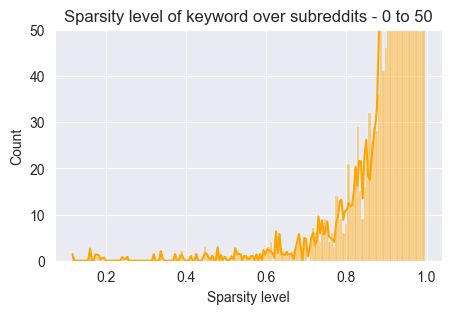

In [6]:
# plot the distribution of total counts of each keyword
keyword_total_counts_over_all_comms = np.sum(keyword_subreddit_matrix, axis=1)

plt.figure(figsize=(5, 3))
# sns.kdeplot(keyword_total_counts_over_all_comms, fill=True, color='blue', alpha=0.5)
# plt.xlim(0, 1000)
# plt.ylim(0, 0.0025)
sns.histplot(keyword_total_counts_over_all_comms, fill=True, color='blue', alpha=0.5, bins=150, kde=True)
plt.title('Distribution of keywords counts over subreddits - full range')
plt.xlabel('Total count (aggregated over all subreddits for each keyword)')
plt.grid(True)
plt.show()

# zoom-ins
plt.figure(figsize=(5, 3))
sns.histplot(keyword_total_counts_over_all_comms, fill=True, color='blue', alpha=0.5, bins=150, kde=True)
plt.title('Distribution of keywords counts over subreddits - 0 to 10000')
plt.xlabel('Total count (aggregated over all subreddits for each keyword)')
plt.ylim(0, 10000)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(keyword_total_counts_over_all_comms, fill=True, color='blue', alpha=0.5, bins=150, kde=True)
plt.title('Distribution of keywords counts over subreddits - 0 to 100')
plt.xlabel('Total count (aggregated over all subreddits for each keyword)')
plt.ylim(0, 100)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(keyword_total_counts_over_all_comms, fill=True, color='blue', alpha=0.5, bins=150, kde=True)
plt.title('Distribution of keywords counts over subreddits - 0 to 40')
plt.xlabel('Total count (aggregated over all subreddits for each keyword)')
plt.ylim(0, 40)
plt.grid(True)
plt.show()

# plot the log+1 distribution of total counts of each keyword
plt.figure(figsize=(5, 3))
sns.histplot(np.log1p(keyword_total_counts_over_all_comms), fill=True, color='skyblue', alpha=0.5, bins=150, kde=True)
plt.title('Log+1 distribution of keywords counts over subreddits - full range')
plt.xlabel('Log+1 of total count (aggregated over all subreddits for each keyword)')
plt.grid(True)
plt.show()
# zoom-ins
plt.figure(figsize=(5, 3))
sns.histplot(np.log1p(keyword_total_counts_over_all_comms), fill=True, color='skyblue', alpha=0.5, bins=150, kde=True)
plt.title('Log+1 distribution of keywords counts over subreddits - 0 to 25000')
plt.xlabel('Log+1 of total count (aggregated over all subreddits for each keyword)')
plt.ylim(0, 25000)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(np.log1p(keyword_total_counts_over_all_comms), fill=True, color='skyblue', alpha=0.5, bins=150, kde=True)
plt.title('Log+1 distribution of keywords counts over subreddits - 0 to 500')
plt.xlabel('Log+1 of total count (aggregated over all subreddits for each keyword)')
plt.ylim(0, 500)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(np.log1p(keyword_total_counts_over_all_comms), fill=True, color='skyblue', alpha=0.5, bins=150, kde=True)
plt.title('Log+1 distribution of keywords counts over subreddits - 0 to 20')
plt.xlabel('Log+1 of total count (aggregated over all subreddits for each keyword)')
plt.ylim(0, 20)
plt.grid(True)
plt.show()

# similarly, plot for the sparsity level of keywords over subreddits
plt.figure(figsize=(5, 3))
sns.histplot(np.mean(keyword_subreddit_matrix == 0, axis=1), bins=150, kde=True, color='orange', alpha=0.5)
plt.title('Sparsity level of keyword over subreddits - full range')
plt.xlabel('Sparsity level')
plt.grid(True)
plt.show()

# zoom-ins (due to the dent in the distribution as seen in the cell below)
plt.figure(figsize=(5, 3))
sns.histplot(np.mean(keyword_subreddit_matrix == 0, axis=1), bins=150, kde=True, color='orange', alpha=0.5)
plt.title('Sparsity level of keyword over subreddits - 0 to 10000')
plt.xlabel('Sparsity level')
plt.ylim(0, 10000)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(np.mean(keyword_subreddit_matrix == 0, axis=1), bins=150, kde=True, color='orange', alpha=0.5)
plt.title('Sparsity level of keyword over subreddits - 0 to 1000')
plt.xlabel('Sparsity level')
plt.ylim(0, 1000)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(np.mean(keyword_subreddit_matrix == 0, axis=1), bins=150, kde=True, color='orange', alpha=0.5)
plt.title('Sparsity level of keyword over subreddits - 0 to 200')
plt.xlabel('Sparsity level')
plt.ylim(0, 200)
plt.grid(True)
plt.show()

plt.figure(figsize=(5, 3))
sns.histplot(np.mean(keyword_subreddit_matrix == 0, axis=1), bins=150, kde=True, color='orange', alpha=0.5)
plt.title('Sparsity level of keyword over subreddits - 0 to 50')
plt.xlabel('Sparsity level')
plt.ylim(0, 50)
plt.grid(True)
plt.show()

In [7]:
# keyword selection
# score = log(count + 1) * coverage
# keyword_subreddit_matrix.shape: (145274, 207)
counts = keyword_subreddit_matrix.sum(axis=1) 
sparsities = np.mean(keyword_subreddit_matrix == 0, axis=1)
coverages = 1 - sparsities
scores = np.log1p(counts) * coverages

# recap
# keyword_subreddit_matrix = pivot_df.to_numpy()
# keywords = pivot_df.index.to_numpy()
# subreddits = pivot_df.columns.to_numpy()

# sort keywords by score from highest to lowest
sorted_indices = np.argsort(scores)[::-1]
# select top k keywords
k = 300
top_k_indices = sorted_indices[:k]
# get the top k keywords and their corresponding counts
top_k_keywords = keywords[top_k_indices]
top_k_counts = counts[top_k_indices]

# get the top k keyword-subreddit matrix
top_k_keyword_subreddit_matrix = keyword_subreddit_matrix[top_k_indices, :]
# check the shape of the top k keyword-subreddit matrix
print(f'Shape of the top {k} keyword-subreddit matrix: {top_k_keyword_subreddit_matrix.shape}')
# check the sparsity of the top k keyword-subreddit matrix
sparsity_top_k = np.mean(top_k_keyword_subreddit_matrix == 0)
print(f'Sparsity of the top {k} keyword-subreddit matrix: {sparsity_top_k:.2%}')

Shape of the top 300 keyword-subreddit matrix: (300, 207)
Sparsity of the top 300 keyword-subreddit matrix: 71.90%


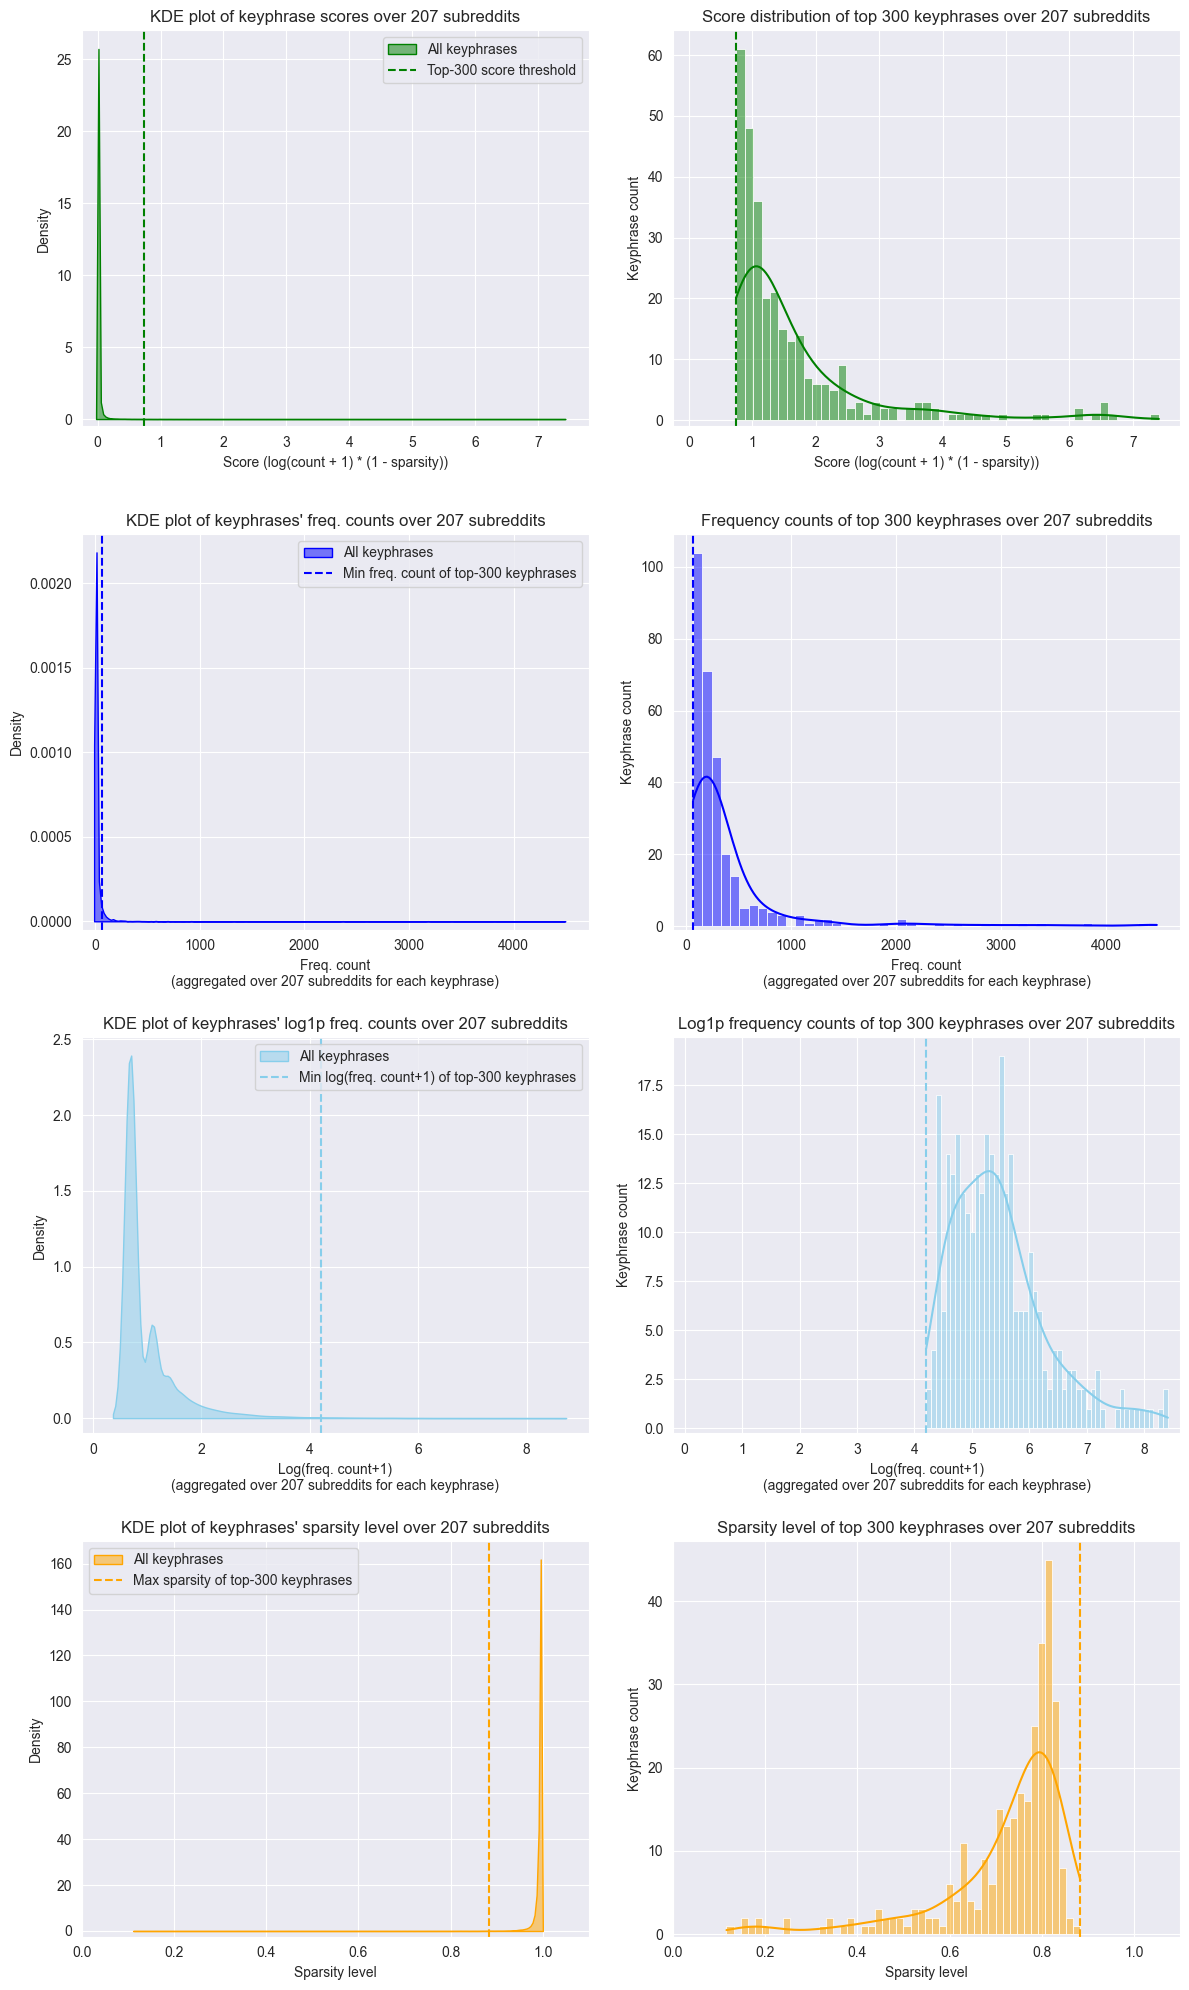

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(12, 20))
axes = axes.flatten()

# plot the score distribution of all keyphrases
sns.kdeplot(scores, fill=True, color='green', alpha=0.5, label='All keyphrases', linewidth=1, ax=axes[0])
axes[0].axvline(np.min(scores[top_k_indices]), color='green', linestyle='--', label=f'Top-{k} score threshold')
axes[0].set_title('KDE plot of keyphrase scores over 207 subreddits')
axes[0].set_xlabel('Score (log(count + 1) * (1 - sparsity))')
axes[0].set_xlim(-0.25, None)
axes[0].set_ylim(-0.5, None)
axes[0].grid(True)
axes[0].legend()

# plot the score distribution of top k keyphrases
sns.histplot(scores[top_k_indices], bins=50, kde=True, color='green', alpha=0.5, ax=axes[1])
axes[1].axvline(np.min(scores[top_k_indices]), color='green', linestyle='--', label=f'Top-{k} score threshold')
axes[1].set_title(f'Score distribution of top {k} keyphrases over 207 subreddits')
axes[1].set_xlabel('Score (log(count + 1) * (1 - sparsity))')
axes[1].set_ylabel("Keyphrase count")
axes[1].set_xlim(-0.25, None)
axes[1].set_ylim(-1, None)
axes[1].grid(True)


# plot the count distribution of all keyphrases
sns.kdeplot(counts, fill=True, color='blue', alpha=0.5, label='All keyphrases', linewidth=1, ax=axes[2])
min_count_top_k = np.min(top_k_counts)
axes[2].axvline(min_count_top_k, color='blue', linestyle='--', label=f'Min freq. count of top-{k} keyphrases')
axes[2].set_title("KDE plot of keyphrases' freq. counts over 207 subreddits")
axes[2].set_xlabel('Freq. count\n(aggregated over 207 subreddits for each keyphrase)')
axes[2].set_xlim(-125, None)
axes[2].set_ylim(-0.00005, None)
axes[2].grid(True)
axes[2].legend()

# plot the count distribution of top k keyphrases
sns.histplot(np.sum(top_k_keyword_subreddit_matrix, axis=1), bins=50, kde=True, color='blue', alpha=0.5, ax=axes[3])
axes[3].axvline(min_count_top_k, color='blue', linestyle='--', label=f'Min freq. count of top-{k} keyphrases')
axes[3].set_title(f"Frequency counts of top {k} keyphrases over 207 subreddits")
axes[3].set_xlabel('Freq. count\n(aggregated over 207 subreddits for each keyphrase)')
axes[3].set_ylabel("Keyphrase count")
axes[3].set_xlim(-125, None)
axes[3].set_ylim(-1, None)
axes[3].grid(True)

# plot the log1p count distribution of all keyphrases
sns.kdeplot(np.log1p(counts), fill=True, color='skyblue', alpha=0.5, label='All keyphrases', linewidth=1, ax=axes[4], bw_adjust=2)
min_log1p_count_top_k = np.min(np.log1p(top_k_counts))
axes[4].axvline(min_log1p_count_top_k, color='skyblue', linestyle='--', label=f'Min log(freq. count+1) of top-{k} keyphrases')
axes[4].set_title("KDE plot of keyphrases' log1p freq. counts over 207 subreddits")
axes[4].set_xlabel('Log(freq. count+1)\n(aggregated over 207 subreddits for each keyphrase)')
axes[4].set_xlim(-0.2, None)
axes[4].set_ylim(-0.1, None)
axes[4].grid(True)
axes[4].legend()

# plot the log1p count distribution of top k keyphrases
sns.histplot(np.log1p(np.sum(top_k_keyword_subreddit_matrix, axis=1)), bins=50, kde=True, color='skyblue', alpha=0.5, ax=axes[5])
axes[5].axvline(min_log1p_count_top_k, color='skyblue', linestyle='--', label=f'Min freq. count of top-{k} keyphrases')
axes[5].set_title(f"Log1p frequency counts of top {k} keyphrases over 207 subreddits")
axes[5].set_xlabel('Log(freq. count+1)\n(aggregated over 207 subreddits for each keyphrase)')
axes[5].set_ylabel("Keyphrase count")
axes[5].set_xlim(-0.2, None)
axes[5].set_ylim(-0.25, None)
axes[5].grid(True)



# plot the sparsity distribution of all keyphrases
sns.kdeplot(sparsities, fill=True, color='orange', alpha=0.5, label='All keyphrases', linewidth=1, ax=axes[6])
max_sparsity = np.max(np.mean(top_k_keyword_subreddit_matrix == 0, axis=1))
axes[6].axvline(max_sparsity, color='orange', linestyle='--', label=f'Max sparsity of top-{k} keyphrases')
axes[6].set_title("KDE plot of keyphrases' sparsity level over 207 subreddits")
axes[6].set_xlabel('Sparsity level')
axes[6].set_xlim(0, 1.1)
axes[6].set_ylim(-2.5, None)
axes[6].grid(True)
axes[6].legend()

# plot the sparsity level of top k keyphrases over subreddits
sns.histplot(np.mean(top_k_keyword_subreddit_matrix == 0, axis=1), bins=50, kde=True, color='orange', alpha=0.5, ax=axes[7])
axes[7].axvline(max_sparsity, color='orange', linestyle='--', label=f'Max sparsity of top-{k} keyphrases')
axes[7].set_title(f'Sparsity level of top {k} keyphrases over 207 subreddits')
axes[7].set_xlabel('Sparsity level')
axes[7].set_ylabel("Keyphrase count")
axes[7].set_xlim(0, 1.1)
axes[7].set_ylim(-0.3, None)
axes[7].grid(True)


plt.tight_layout(h_pad=2.0, w_pad=2.0)
plt.savefig("appendix_keyphrase_sampling.pdf", bbox_inches='tight', dpi = 300)
plt.show()